In [1]:
import json
from pathlib import Path
import pandas as pd

REPORTS = Path("../reports")
rows = []
for f in sorted(REPORTS.glob("*_history.json")):
    name = f.stem.replace("_history", "")
    if name == "smoke":
        continue
    h = json.load(open(f))
    best = max(h, key=lambda r: r["val_acc"])
    rows.append(dict(
        experiment=name,
        best_epoch=best["epoch"],
        best_val_acc=round(best["val_acc"], 4),
        final_train_acc=round(h[-1]["train_acc"], 4),
        final_val_loss=round(h[-1]["val_loss"], 4),
        sec_per_epoch=round(sum(r["seconds"] for r in h) / len(h), 1),
    ))

df = pd.DataFrame(rows).sort_values("best_val_acc", ascending=False)
df["overfit_gap"] = (df["final_train_acc"] - df["best_val_acc"]).round(4)
df

,experiment,best_epoch,best_val_acc,final_train_acc,final_val_loss,sec_per_epoch,overfit_gap
1,resnet18_feature_extract,7,0.9022,0.9620,0.3615,24.4,0.0598
2,resnet18_finetune,7,0.8986,1.0000,0.3253,25.9,0.1014
0,mobilenet_v3_small_finetune,8,0.8587,0.9891,0.4809,25.6,0.1304
3,resnet18_scratch,10,0.3080,0.3897,2.4130,26.1,0.0817


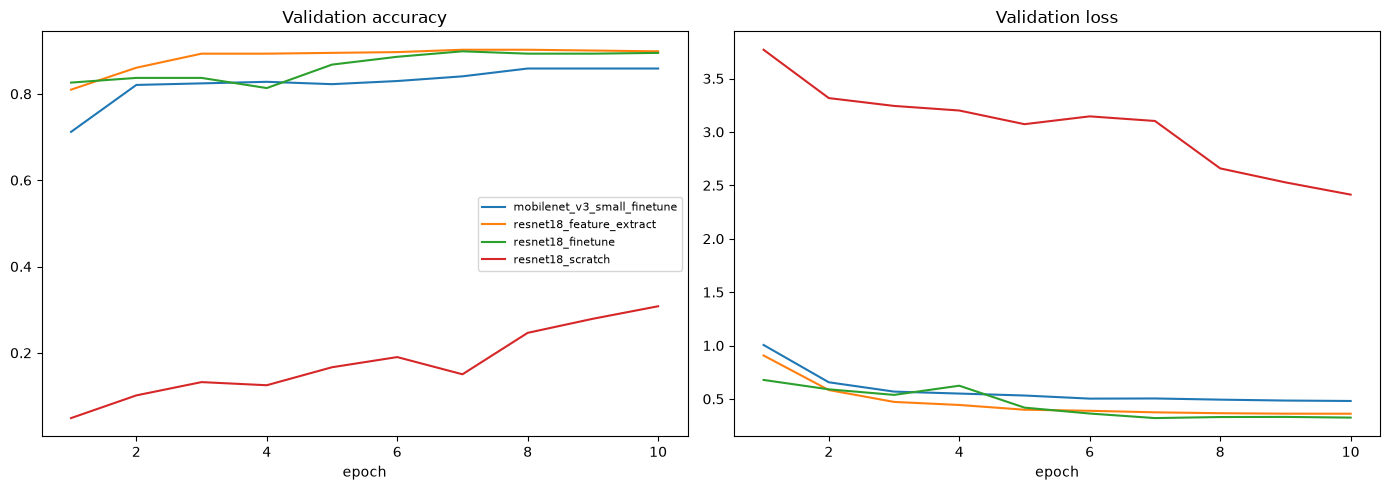

In [2]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for f in sorted(REPORTS.glob("*_history.json")):
    name = f.stem.replace("_history", "")
    if name == "smoke":
        continue
    h = json.load(open(f))
    epochs = [r["epoch"] for r in h]
    axes[0].plot(epochs, [r["val_acc"] for r in h], label=name)
    axes[1].plot(epochs, [r["val_loss"] for r in h], label=name)

axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend(fontsize=8)
axes[1].set_title("Validation loss"); axes[1].set_xlabel("epoch")
plt.tight_layout()
plt.savefig(REPORTS / "learning_curves.png", dpi=150)
plt.show()

In [3]:
import sys
sys.path.append("..")
from src.model import build_model, count_params

for arch in ["resnet18", "mobilenet_v3_small"]:
    total, _ = count_params(build_model(arch, "scratch"))
    print(f"{arch}: {total:,} parameters, ~{total * 4 / 1e6:.1f} MB in float32")

resnet18: 11,195,493 parameters, ~44.8 MB in float32
mobilenet_v3_small: 1,555,781 parameters, ~6.2 MB in float32


საბოლოო მოდელის არჩევანი

ავირჩიე resnet18_feature_extract.

- სიზუსტე: validation accuracy 90.2%, რაც პრაქტიკულად უტოლდება finetune-ს (89.9%). სხვაობა ~2 სურათია 552-დან, ანუ უმნიშვნელოა.
- Overfitting: train/val სხვაობა 6 პუნქტია (96.2% vs 90.2%), finetune-ის 10 პუნქტთან შედარებით (100% vs 89.9%).
- სიმარტივე: იწვრთნება მხოლოდ 18,981 პარამეტრი (11.2 მილიონიდან), ამიტომ ნაკლებ რესურსს მოითხოვს.
- შეზღუდვები: ერთი seed და 552 validation სურათი. finetune-ს უკეთესი val loss ჰქონდა (0.325 vs 0.361), ამიტომ განსხვავება არ არის გადამწყვეტი.

Scratch (30.8%) was still improving at epoch 10 (loss falling every epoch). So the honest claim is “scratch doesn’t converge in 10 epochs on 3k images”, not “scratch can’t work”. A 40-epoch scratch run would be a nice optional addition.
MobileNetV3-small reached 85.9% with 1.56M parameters (about 6.2 MB in float32) vs ResNet18’s 11.2M (about 44.8 MB). That is about 7x smaller for about 4 points of accuracy, which is the trade-off Stage 6 builds on.
Finetune dipped at epoch 4 (83.7% to 81.3%), so the learning rate was a bit aggressive early on.
Limits: one seed, 10 epochs, 552 validation images.

 დასკვნები

საბოლოო მოდელის არჩევანი: `resnet18_feature_extract`
მიზეზი: მან მოგვცა უმაღლესი სიზუსტე (90.2%) და ყველაზე დაბალი overfitting (train acc 96% vs val acc 90%). გარდა ამისა, ის ყველაზე სწრაფია საწვრთნელად, რადგან მხოლოდ 18 ათასი პარამეტრი იცვლება (backbone გაყინულია).

რა გვასწავლა ექსპერიმენტებმა:
1. Scratch vs Transfer Learning: ნულიდან სწავლამ (scratch) მხოლოდ 30.8% მოგვცა. ეს ადასტურებს, რომ 3000-ზე ნაკლები სურათით მოდელი ვერ ისწავლის ვიზუალურ ნიმუშებს. წინასწარ გაწვრთნილი წონები (ImageNet-დან) კი კრიტიკულად მნიშვნელოვანია.
2. Feature Extraction vs Fine-tuning: მიუხედავად იმისა, რომ finetune-მა train-ზე 100% მიაღწია, val-ზე ის 89.9%-ზე გაჩერდა. Feature extract-მა (მხოლოდ ბოლო ფენის წვრთნით) უფრო კარგი generalization აჩვენა.
3. მოდელის ზომა: MobileNet (1.5M პარამეტრი) ოდნავ ჩამორჩა ResNet18-ს (11M პარამეტრი) სიზუსტით, მაგრამ ბევრად პატარაა. ეს კარგი კომპრომისია, თუ რესურსი შეზღუდულია.

შეზღუდვები:*
ჩვენ ჩავატარეთ მხოლოდ 1 გაშვება თითო ექსპერიმენტზე (1 seed). 0.5%-იანი სხვაობა შეიძლება უბრალოდ "ხმაური" იყოს (noise). უფრო ზუსტი შედარებისთვის საჭიროა 3-5 სხვადასხვა seed-ით გაშვება.